# Résultats sur DONNÉES FICTIVES

Exécuté avec Spark local sur une table **simulée** de 6 terminaux d'une même zone (2024 à novembre 2026, 1 million d'opérations), sans date de manifestation renseignée. Cas simulé : TERMINAL91001 ne fonctionne plus depuis le 25/10/2026 ; TERMINAL91003 dégradé depuis le 28/10/2026 (activité -60 %, plus de captures) ; TERMINAL91005 voisin qui récupère les clients (+35 %) ; TERMINAL91006 avec une panne isolée en septembre (ne doit pas être signalée) ; TERMINAL91002 et TERMINAL91004 inchangés. **Les chiffres n'ont aucune valeur réelle.**


# Impact des manifestations sur l'activité de terminaux dégradés

**Point de départ.** Les terminaux étudiés ont été choisis par ville : on ne sait pas à l'avance lesquels ont été
touchés. La section 4 trie donc d'abord les terminaux : comportement **changé** ou **inchangé** sur les derniers jours.

**Objectif.** Pour chaque terminal étudié, établir son comportement **normal** (habitude par jour de semaine,
saisonnalité, profil horaire, composition des opérations), puis démontrer s'il y a eu **rupture** après la
dégradation : terminal hors service, activité réduite, fonctionnement intermittent, ou absence d'impact.

**Méthode.**
1. Une ligne par terminal et par jour, calendrier complété par des 0 : un terminal hors service ne produit aucune ligne,
   c'est donc l'absence d'opérations qui se mesure.
2. **Activité attendue** (contrefactuel) : habitude du terminal par jour de semaine sur les 6 mois précédant la
   dégradation, corrigée de la saisonnalité observée l'année précédente sur la même période.
3. **Date de rupture** : déclarée (si connue) et détectée (premier jour où l'activité sur 7 jours tombe sous
   50 % de l'habitude) ; les deux sont comparées.
4. **KPI avant / après / même période N-1**, test statistique, retraits non servis et montants non distribués.

Exécuter les cellules dans l'ordre. Seule la section 1 se modifie.

## 0. Imports et session Spark

In [1]:
import math

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from matplotlib.colors import LinearSegmentedColormap
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.enableHiveSupport().getOrCreate()
pd.set_option("display.max_columns", 60)

## 1. Configuration
Seul le **bloc à compléter** se modifie. Si les dates de dégradation sont inconnues, laisser `{}` : elles sont
détectées dans les données (section 6).

In [2]:
# ============================================================================================================
# BLOC À COMPLÉTER
# ============================================================================================================
DATASET_OPERATIONS = None        # dataset du select * sur les terminaux dégradés (3 ans)
TERMINAL_ETUDIES = None                           # None = tous les terminaux du dataset ; sinon ["num1", "num2", ...]
DATE_MANIFESTATION = None                    # "AAAA-MM-JJ" : date des manifestations (repère des graphiques)
DATES_DEGRADATION = {}                       # {"num_automate": "AAAA-MM-JJ"} si la date de chaque terminal est connue

# ============================================================================================================
# NE PAS MODIFIER : format de la requête d'entrée (identique au projet principal)
# ============================================================================================================
TABLE_HIVE_OPERATIONS = "ops_fictives"                # ou "base.table" si lecture Hive directe
COLONNES = {
    "num_automate": "num_automate", "date_operation": "date_operation", "heure_operation": "heure_operation",
    "montant_ope": "montant_ope", "lib_ope": "lib_ope", "top_annule": "top_annul",
    "motif_capture": "lib_motif_capture_carte", "type_client": "type_porteur",
    "libelle_site": "lib_site_implantation", "code_postal": "cd_pst", "ville": "ville",
    "longitude": "longitude", "latitude": "latitude",
    "nb1": "nb_billetsk_7_1", "nb2": "nb_billetsk_7_2", "nb3": "nb_billetsk_7_3", "nb4": "nb_billetsk_7_4",
    "coupure1": "val_coupurek_7_1", "coupure2": "val_coupurek_7_2",
    "coupure3": "val_coupurek_7_3", "coupure4": "val_coupurek_7_4",
}
TYPES_OPERATION = [("%AUTORISATION%", "RETRAIT"), ("%CAPTURE%", "CAPTURE"), ("%RETRAIT%", "RETRAIT")]
VALEUR_PORTEUR = "Porteur"
FORMAT_DATE = "ddMMyyyy"                     # format de date_operation
DIVISEUR_MONTANT = 100                       # montant_ope en centimes
DIVISEUR_COUPURE = 100                       # val_coupurek en centimes (5000 = billet de 50 €)

# --- paramètres de la méthode
JOURS_REFERENCE = 182        # période « normale » : 6 mois avant la dégradation...
JOURS_EXCLUS_AVANT = 7       # ... hors la dernière semaine (manifestations déjà en cours)
JOURS_RECENTS = 14           # fenêtre « derniers jours » examinée par le tri (section 4)
JOURS_RECHERCHE = 60         # sans DATE_MANIFESTATION : rupture recherchée sur les 60 derniers jours
SEUIL_RUPTURE = 0.5          # rupture : activité sur 7 jours < 50 % de l'habitude
SEUIL_REPRISE = 0.8          # reprise : activité sur 7 jours >= 80 % de l'attendu
SEUIL_HORS_SERVICE = 0.1     # hors service : < 10 % de l'attendu sur les 28 derniers jours
DATASET_SORTIE_SYNTHESE = None   # ex. "impact_manifestations_synthese" (dataset à créer dans le Flow)

## 2. Fonctions d'affichage
Tableaux et chiffres clés en HTML simple (pas de dépendance à jinja2) ; une palette unique pour tous les
graphiques : bleu = observé, gris = attendu ou période de référence, trait noir = dégradation.

In [3]:
BLEU, GRIS, GRIS_CLAIR, ORANGE, ENCRE = "#2a78d6", "#8a8984", "#d9d8d3", "#eb6834", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ececea", "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ae",
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9,
                     "axes.prop_cycle": plt.cycler(color=[BLEU, GRIS, ORANGE])})
CSS = """<style>
.kpi-grille{display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 14px}
.kpi{border:1px solid #e3e2de;border-radius:8px;padding:10px 14px;min-width:150px;background:#fcfcfb}
.kpi .v{font-size:22px;font-weight:700;color:#0b0b0b}.kpi .l{font-size:12px;color:#52514e}
table.t{border-collapse:collapse;font-size:12px;margin:4px 0 12px}
table.t th{background:#f3f2ef;color:#0b0b0b;text-align:left;padding:5px 9px;border-bottom:2px solid #d9d8d3}
table.t td{padding:4px 9px;border-bottom:1px solid #ecebe8;text-align:right}
table.t td.txt{text-align:left}.neg{color:#c4380f;font-weight:600}.pos{color:#1a7f37;font-weight:600}
.note{color:#52514e;font-size:12.5px;margin:2px 0 10px;max-width:900px}
</style>"""


def afficher_titre(titre, note=None):
    """Titre de résultat et explication courte."""
    html = CSS + "<h4 style='margin:10px 0 2px'>{}</h4>".format(titre)
    if note:
        html += "<div class='note'>{}</div>".format(note)
    display(HTML(html))


def afficher_chiffres(chiffres, titre=None):
    """Chiffres clés en tuiles : {libellé: valeur}."""
    tuiles = "".join("<div class='kpi'><div class='v'>{}</div><div class='l'>{}</div></div>".format(
        formater(v), k) for k, v in chiffres.items())
    display(HTML(CSS + ("<h4 style='margin:10px 0 2px'>{}</h4>".format(titre) if titre else "") +
                 "<div class='kpi-grille'>{}</div>".format(tuiles)))


def formater(v):
    """Nombre lisible : séparateur de milliers, 1 décimale au plus."""
    if isinstance(v, (int, np.integer)):
        return "{:,}".format(int(v)).replace(",", " ")
    if isinstance(v, (float, np.floating)):
        if np.isnan(v):
            return "–"
        return "{:,.1f}".format(v).replace(",", " ") if abs(v) < 1000 else "{:,.0f}".format(v).replace(",", " ")
    return "" if v is None else str(v)


def afficher_tableau(table, titre=None, note=None, colonnes_variation=(), max_lignes=60):
    """Tableau HTML ; les colonnes de variation (%) sont colorées (baisse en rouge, hausse en vert)."""
    entete = "".join("<th>{}</th>".format(c) for c in table.columns)
    corps = []
    for _, ligne in table.head(max_lignes).iterrows():
        cellules = []
        for c in table.columns:
            v = ligne[c]
            classe = "txt" if isinstance(v, str) else ""
            if c in colonnes_variation and isinstance(v, (int, float, np.number)) and not pd.isna(v):
                classe = "neg" if v <= -20 else ("pos" if v >= 20 else "")
                v = "{:+.0f} %".format(v)
            cellules.append("<td class='{}'>{}</td>".format(classe, echapper(formater(v))))
        corps.append("<tr>{}</tr>".format("".join(cellules)))
    if titre:
        afficher_titre(titre, note)
    display(HTML(CSS + "<table class='t'><tr>{}</tr>{}</table>".format(entete, "".join(corps))))


def echapper(texte):
    """Texte sûr dans du HTML (les signes < et > ne sont pas pris pour des balises)."""
    return str(texte).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")


def marquer_degradation(ax, date, libelle=True):
    """Trait vertical noir à la date de dégradation."""
    if date is not None and not pd.isna(date):
        ax.axvline(date, color=ENCRE, linewidth=1.2)
        if libelle:
            ax.annotate("dégradation", (date, 1), xycoords=("data", "axes fraction"), xytext=(3, -10),
                        textcoords="offset points", fontsize=8, color=ENCRE)


def axe_dates(ax):
    """Axe des dates lisible (mois abrégés)."""
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    for etiquette in ax.get_xticklabels():
        etiquette.set_fontsize(7)

## 3. Lecture et agrégation par terminal et par jour
La table brute n'est lue qu'une fois : Spark calcule les agrégats (terminal x jour, terminal x jour x heure,
terminal x mois x coupure, terminal x mois x motif de capture), qui sont seuls ramenés en pandas.

In [4]:
def lire_table(dataset=None, table_hive=None):
    """Lit la table brute : dataset Dataiku (recommandé) ou table Hive."""
    if dataset:
        import dataiku
        import dataiku.spark as dkuspark
        from pyspark.sql import SQLContext
        return dkuspark.get_dataframe(SQLContext(spark.sparkContext), dataiku.Dataset(dataset))
    return spark.table(table_hive)


def preparer_operations(source, colonnes, terminal_etudies=None):
    """Colonnes typées : date, heure, montant, type d'opération, indicateurs retrait / annulé / capture / confrère."""
    present = {cle: nom for cle, nom in colonnes.items() if nom in source.columns}
    manquantes = [c for c in ("num_automate", "date_operation", "lib_ope") if c not in present]
    if manquantes:
        raise ValueError("Colonnes introuvables : {}".format([colonnes[c] for c in manquantes]))
    col = lambda cle, defaut=None: F.col(present[cle]) if cle in present else F.lit(defaut)
    texte_date = F.lpad(F.trim(col("date_operation").cast("string")), 8, "0")
    heure = F.lpad(F.regexp_replace(F.trim(col("heure_operation", "").cast("string")), "[^0-9]", ""), 6, "0")
    libelle = F.upper(F.trim(col("lib_ope").cast("string")))
    type_op = F.lit("AUTRE")
    for motif, valeur in reversed(TYPES_OPERATION):   # le premier motif de la liste l'emporte
        type_op = F.when(libelle.like(motif), F.lit(valeur)).otherwise(type_op)
    ops = source.select(
        F.trim(col("num_automate").cast("string")).alias("num_automate"),
        F.to_date(texte_date, FORMAT_DATE).alias("date"),
        F.substring(heure, 1, 2).cast("int").alias("heure"),
        (col("montant_ope", 0).cast("double") / DIVISEUR_MONTANT).alias("montant"),
        type_op.alias("type_op"),
        (F.trim(col("top_annule", "0").cast("string")) == "1").cast("int").alias("annule"),
        F.upper(F.trim(col("motif_capture", "").cast("string"))).alias("motif_capture"),
        F.when(col("type_client").isNull(), F.lit(None))
         .otherwise((F.trim(col("type_client").cast("string")) != VALEUR_PORTEUR).cast("int")).alias("confrere"),
        *[col(c).cast("string").alias(c) for c in ("libelle_site", "code_postal", "ville", "longitude", "latitude")],
        *[col("nb{}".format(i), 0).cast("double").alias("nb{}".format(i)) for i in range(1, 5)],
        *[(col("coupure{}".format(i), 0).cast("double") / DIVISEUR_COUPURE).alias("coupure{}".format(i))
          for i in range(1, 5)])
    if terminal_etudies:
        ops = ops.filter(F.col("num_automate").isin([str(g) for g in terminal_etudies]))
    retrait = (F.col("type_op") == "RETRAIT")
    return (ops.withColumn("retrait", (retrait & (F.col("annule") == 0)).cast("int"))
               .withColumn("retrait_annule", (retrait & (F.col("annule") == 1)).cast("int"))
               .withColumn("capture", (F.col("type_op") == "CAPTURE").cast("int")))


source = lire_table(DATASET_OPERATIONS, TABLE_HIVE_OPERATIONS)
ops = preparer_operations(source, COLONNES, TERMINAL_ETUDIES).persist()
qualite = ops.agg(F.count("*").alias("lignes"), F.sum(F.col("date").isNull().cast("int")).alias("dates_illisibles"),
                  F.sum(F.col("heure").isNull().cast("int")).alias("heures_illisibles"),
                  F.sum((F.col("type_op") == "AUTRE").cast("int")).alias("libelles_non_reconnus"),
                  F.countDistinct("num_automate").alias("terminal"), F.min("date").alias("premier_jour"),
                  F.max("date").alias("dernier_jour")).toPandas()
afficher_tableau(qualite, "Contrôle de lecture",
                 "Dates ou heures illisibles et libellés non reconnus doivent être à 0 (ou marginaux).")

lignes,dates_illisibles,heures_illisibles,libelles_non_reconnus,terminal,premier_jour,dernier_jour
1 156 313,0,0,0,6,2024-01-01,2026-11-02


In [5]:
def agreger_jour(ops):
    """Une ligne par terminal et par jour d'activité."""
    retrait = F.col("retrait") == 1
    return ops.filter(F.col("date").isNotNull()).groupBy("num_automate", "date").agg(
        F.count("*").alias("operations"), F.sum("retrait").alias("retraits"),
        F.sum("retrait_annule").alias("retraits_annules"), F.sum("capture").alias("captures"),
        F.sum(F.when(retrait, F.col("montant")).otherwise(0)).alias("montant"),
        F.sum(F.when(retrait, F.col("confrere"))).alias("retraits_confreres"),
        F.countDistinct(F.when(retrait, F.col("heure"))).alias("heures_actives"),
        F.min(F.when(retrait, F.col("heure"))).alias("premiere_heure"),
        F.max(F.when(retrait, F.col("heure"))).alias("derniere_heure")).toPandas()


def agreger_heure(ops):
    """Retraits par terminal, jour et heure (profil horaire)."""
    return (ops.filter((F.col("retrait") == 1) & F.col("date").isNotNull())
            .groupBy("num_automate", "date", "heure").agg(F.count("*").alias("retraits")).toPandas())


def agreger_coupures(ops):
    """Billets délivrés par terminal, mois et valeur de coupure (cassette vide ou vidée = coupure qui disparaît)."""
    mois = F.trunc(F.col("date"), "month")
    morceaux = [ops.filter(F.col("retrait") == 1).select("num_automate", mois.alias("mois"),
                                                         F.col("coupure{}".format(i)).alias("coupure"),
                                                         F.col("nb{}".format(i)).alias("billets"))
                for i in range(1, 5)]
    union = morceaux[0]
    for m in morceaux[1:]:
        union = union.union(m)
    return (union.filter(F.col("billets") > 0).groupBy("num_automate", "mois", "coupure")
            .agg(F.sum("billets").alias("billets")).toPandas())


def agreger_motifs(ops):
    """Captures par terminal, mois et motif."""
    return (ops.filter(F.col("capture") == 1)
            .groupBy("num_automate", F.trunc(F.col("date"), "month").alias("mois"), "motif_capture")
            .agg(F.count("*").alias("captures")).toPandas())


def referentiel_terminal(ops):
    """Fiche d'identité : site, ville, code postal, coordonnées, période d'activité."""
    return ops.groupBy("num_automate").agg(
        F.first("libelle_site", True).alias("site"), F.first("ville", True).alias("ville"),
        F.first("code_postal", True).alias("code_postal"), F.first("latitude", True).alias("latitude"),
        F.first("longitude", True).alias("longitude"), F.min("date").alias("premiere_operation"),
        F.max("date").alias("derniere_operation"), F.count("*").alias("operations")).toPandas()


jour_brut = agreger_jour(ops)
heure_brut = agreger_heure(ops)
coupures = agreger_coupures(ops)
motifs = agreger_motifs(ops)
fiche = referentiel_terminal(ops).sort_values("num_automate").reset_index(drop=True)
ops.unpersist()
for table in (jour_brut, heure_brut):
    table["date"] = pd.to_datetime(table["date"])
for table in (coupures, motifs):
    table["mois"] = pd.to_datetime(table["mois"])
afficher_tableau(fiche, "Fiche d'identité des terminaux étudiés",
                 "Dernière opération très antérieure à la fin des données = terminal qui ne fonctionne plus.")

num_automate,site,ville,code_postal,latitude,longitude,premiere_operation,derniere_operation,operations
TERMINAL91001,Centre commercial,Paris,75011,48.859,2.379,2024-01-01,2026-10-24,234 709
TERMINAL91002,Agence,Lyon,69002,45.76,4.832,2024-01-01,2026-11-02,171 863
TERMINAL91003,Gare,Nantes,44000,47.217,-1.542,2024-01-01,2026-11-02,277 542
TERMINAL91004,Agence,Bordeaux,33000,44.837,-0.579,2024-01-01,2026-11-02,128 374
TERMINAL91005,Agence,Rennes,35000,48.111,-1.678,2024-01-01,2026-11-02,150 694
TERMINAL91006,Centre commercial,Toulouse,31000,43.604,1.444,2024-01-01,2026-11-02,193 131


In [6]:
def completer_calendrier(jour_brut):
    """Calendrier complet pour chaque terminal, du premier au dernier jour des données : les jours sans opération
    deviennent des 0 (c'est ainsi que se voit un terminal hors service)."""
    jours = pd.date_range(jour_brut["date"].min(), jour_brut["date"].max(), freq="D")
    grille = pd.MultiIndex.from_product([sorted(jour_brut["num_automate"].unique()), jours],
                                        names=["num_automate", "date"])
    table = jour_brut.set_index(["num_automate", "date"]).reindex(grille).reset_index()
    comptes = ["operations", "retraits", "retraits_annules", "captures", "montant", "retraits_confreres",
               "heures_actives"]
    table[comptes] = table[comptes].fillna(0)
    table["jour_semaine"] = table["date"].dt.dayofweek
    table["sans_retrait"] = (table["retraits"] == 0).astype(int)
    return table


journees = completer_calendrier(jour_brut)
LISTE_TERMINAL = sorted(journees["num_automate"].unique())
FIN_DONNEES = journees["date"].max()
afficher_chiffres({"terminal étudiés": len(LISTE_TERMINAL), "jours couverts": journees["date"].nunique(),
                   "premier jour": journees["date"].min().strftime("%d/%m/%Y"),
                   "dernier jour": FIN_DONNEES.strftime("%d/%m/%Y"),
                   "retraits au total": int(journees["retraits"].sum())}, "Table terminal x jour")

## 4. Tri des terminaux : quels terminal ont changé de comportement ces derniers jours ?
Les terminaux ont été choisis par ville : certains ont pu être touchés, d'autres non. Pour chaque terminal, on compare
les `JOURS_RECENTS` (14) derniers jours à son **habitude** : moyenne des mêmes jours de semaine des 8 semaines
qui précèdent la fenêtre. Trois repères évitent les fausses alertes :
- **rang dans l'année** : le même calcul est refait sur toutes les fenêtres de 14 jours des 12 derniers mois ;
  un niveau jamais (ou presque jamais) atteint en un an n'est pas une fluctuation ordinaire ;
- **même période l'an dernier** : si l'an dernier la même fenêtre était déjà basse (vacances, Toussaint), la
  baisse est saisonnière ;
- **autres signaux** : heures d'activité, montant moyen, captures, annulations (terminal ouvert mais endommagé).

| Statut | Règle |
|---|---|
| Arrêté | au moins 3 derniers jours sans retrait, ou moins de 10 % de l'habitude |
| Baisse marquée | sur 14 jours ou sur les 7 derniers : moins de 70 % de l'habitude, niveau parmi les 2 % les plus bas de l'année, pas saisonnier |
| Hausse marquée | sur 14 jours ou sur les 7 derniers : plus de 130 % de l'habitude, niveau parmi les 2 % les plus hauts de l'année, pas saisonnier |
| À surveiller | au moins 2 jours sous 50 % de l'habitude, ou niveau parmi les 5 % extrêmes, ou autre signal |
| Inchangé | aucun des cas précédents |

In [7]:
def rapport_fenetre(retraits, jours_semaine, debut, n):
    """Retraits des jours debut..debut+n-1 / habitude (mêmes jours de semaine des 8 semaines avant debut)."""
    if debut < 56:
        return np.nan, np.nan
    reference = pd.Series(retraits[debut - 56:debut]).groupby(jours_semaine[debut - 56:debut]).mean()
    attendu = reference.reindex(jours_semaine[debut:debut + n]).values.sum()
    return (retraits[debut:debut + n].sum() / attendu if attendu > 0 else np.nan), attendu


def indicateurs_periode(t):
    """Heures actives, montant moyen, captures pour 1000 opérations, part d'annulations."""
    retraits = t["retraits"].sum()
    return {"heures": t["heures_actives"].mean(),
            "montant_moyen": t["montant"].sum() / retraits if retraits else np.nan,
            "captures": 1000 * t["captures"].sum() / max(t["operations"].sum(), 1),
            "annules": 100 * t["retraits_annules"].sum() / max(retraits + t["retraits_annules"].sum(), 1)}


def autres_signaux(recent, reference):
    """Changements de fonctionnement d'un terminal encore actif."""
    r, a = indicateurs_periode(recent), indicateurs_periode(reference)
    signaux = []
    if a["heures"] and r["heures"] < 0.8 * a["heures"]:
        signaux.append("heures d'activité {:.0f} → {:.0f}".format(a["heures"], r["heures"]))
    if a["montant_moyen"] and r["montant_moyen"] < 0.8 * a["montant_moyen"]:
        signaux.append("montant moyen {:.0f} → {:.0f} €".format(a["montant_moyen"], r["montant_moyen"]))
    if r["captures"] >= 3 and r["captures"] > 2 * a["captures"]:
        signaux.append("captures {:.0f} → {:.0f} pour 1000".format(a["captures"], r["captures"]))
    if r["annules"] >= 3 and r["annules"] > 2 * a["annules"]:
        signaux.append("annulations {:.1f} → {:.1f} %".format(a["annules"], r["annules"]))
    return signaux


def mesurer_fenetre(retraits, jours_semaine, n):
    """Rapport à l'habitude des n derniers jours, son rang parmi les fenêtres de n jours des 12 derniers mois
    (sans chevauchement avec la fenêtre récente) et le même rapport un an plus tôt."""
    debut = len(retraits) - n
    rapport, attendu = rapport_fenetre(retraits, jours_semaine, debut, n)
    historique = np.array([rapport_fenetre(retraits, jours_semaine, d, n)[0]
                           for d in range(max(56, debut - 365), debut - n + 1)])
    historique = historique[~np.isnan(historique)]
    n_1 = rapport_fenetre(retraits, jours_semaine, debut - 364, n)[0] if debut - 364 >= 56 else np.nan
    return {"rapport": rapport, "attendu": attendu, "n_1": n_1,
            "rang": (historique <= rapport).mean() if len(historique) else np.nan,
            "saisonnier": not np.isnan(n_1) and abs(rapport - n_1) < 0.15}


def trier_terminal(journees, n=JOURS_RECENTS):
    """Un statut par terminal sur les n derniers jours (et sur les 7 derniers, pour un changement très récent), avec
    les éléments qui le justifient."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = journees[journees["num_automate"] == terminal].sort_values("date").reset_index(drop=True)
        retraits, jours_semaine = t["retraits"].values.astype(float), t["jour_semaine"].values
        debut = len(t) - n
        fenetres = [mesurer_fenetre(retraits, jours_semaine, n), mesurer_fenetre(retraits, jours_semaine, 7)]
        rapport, attendu, n_1 = fenetres[0]["rapport"], fenetres[0]["attendu"], fenetres[0]["n_1"]
        baisse = any(f["rapport"] < 0.7 and f["rang"] <= 0.02 and not f["saisonnier"] for f in fenetres)
        hausse = any(f["rapport"] > 1.3 and f["rang"] >= 0.98 and not f["saisonnier"] for f in fenetres)
        extreme = any(f["rang"] <= 0.05 or f["rang"] >= 0.95 for f in fenetres)
        recent, reference = t.iloc[debut:], t.iloc[debut - 56:debut]
        habitude_jour = reference.groupby("jour_semaine")["retraits"].mean()
        attendu_jour = recent["jour_semaine"].map(habitude_jour)
        jours_bas = int((recent["retraits"] < SEUIL_RUPTURE * attendu_jour).sum())
        zeros_fin = int(len(recent) - recent["retraits"].to_numpy().nonzero()[0].max() - 1) \
            if recent["retraits"].sum() else len(recent)
        premier_bas = recent.loc[recent["retraits"] < SEUIL_RUPTURE * attendu_jour, "date"].min()
        signaux = autres_signaux(recent[recent["retraits"] > 0], reference)
        if zeros_fin >= 3 or rapport < SEUIL_HORS_SERVICE:
            statut = "Arrêté"
        elif baisse:
            statut = "Baisse marquée"
        elif hausse:
            statut = "Hausse marquée"
        elif jours_bas >= 2 or extreme or signaux:
            statut = "À surveiller"
        else:
            statut = "Inchangé"
        pct = lambda v: round(100 * v, 0) if not np.isnan(v) else np.nan
        lignes.append({
            "terminal": terminal, "statut": statut,
            "activité / habitude (%)": pct(rapport),
            "7 derniers jours (%)": pct(fenetres[1]["rapport"]),
            "même période N-1 (%)": pct(n_1),
            "rang dans l'année (%)": "{:.0f} / {:.0f}".format(pct(fenetres[0]["rang"]), pct(fenetres[1]["rang"])),
            "retraits": int(recent["retraits"].sum()), "attendus": int(round(attendu)),
            "jours sous 50 %": jours_bas, "derniers jours sans retrait": zeros_fin,
            "premier jour sous 50 %": premier_bas.strftime("%d/%m/%Y") if not pd.isna(premier_bas) else "–",
            "autres signaux": " ; ".join(signaux) or "–"})
    ordre = {"Arrêté": 0, "Baisse marquée": 1, "Hausse marquée": 2, "À surveiller": 3, "Inchangé": 4}
    table = pd.DataFrame(lignes)
    table["_ordre"] = table["statut"].map(ordre)
    return (table.sort_values(["_ordre", "activité / habitude (%)"]).drop(columns="_ordre")
            .reset_index(drop=True))


tri = trier_terminal(journees)
afficher_chiffres({"terminal examinés": len(tri),
                   "comportement changé": int(tri["statut"].isin(["Arrêté", "Baisse marquée", "Hausse marquée"]).sum()),
                   "à surveiller": int((tri["statut"] == "À surveiller").sum()),
                   "inchangés": int((tri["statut"] == "Inchangé").sum()),
                   "fenêtre examinée": "{} au {}".format((FIN_DONNEES - pd.Timedelta(days=JOURS_RECENTS - 1))
                                                         .strftime("%d/%m"), FIN_DONNEES.strftime("%d/%m/%Y"))},
                  "Tri des terminaux sur les {} derniers jours".format(JOURS_RECENTS))
afficher_tableau(tri, "Statut de chaque terminal",
                 "activité / habitude : retraits des derniers jours en % de l'habitude du terminal. Rang dans l'année : "
                 "part des fenêtres de même durée des 12 derniers mois avec une activité inférieure ou égale, sur 14 "
                 "jours / sur 7 jours (0 % = niveau le plus bas de l'année, 100 % = le plus haut). Même période N-1 : le même rapport un an plus tôt ; s'il est "
                 "proche, la variation est saisonnière.")

terminal,statut,activité / habitude (%),7 derniers jours (%),même période N-1 (%),rang dans l'année (%),retraits,attendus,jours sous 50 %,derniers jours sans retrait,premier jour sous 50 %,autres signaux
TERMINAL91001,Arrêté,37.0,0.0,93.0,0 / 0,1 168,3 142,9,9,25/10/2026,–
TERMINAL91003,Baisse marquée,68.0,43.0,94.0,0 / 0,2 563,3 789,6,0,28/10/2026,captures 4 → 15 pour 1000
TERMINAL91005,À surveiller,115.0,124.0,92.0,94 / 99,2 319,2 020,0,0,–,–
TERMINAL91004,Inchangé,93.0,98.0,94.0,18 / 47,1 605,1 724,0,0,–,–
TERMINAL91006,Inchangé,93.0,95.0,93.0,16 / 27,2 380,2 556,0,0,–,–
TERMINAL91002,Inchangé,94.0,92.0,95.0,18 / 11,2 204,2 350,0,0,–,–


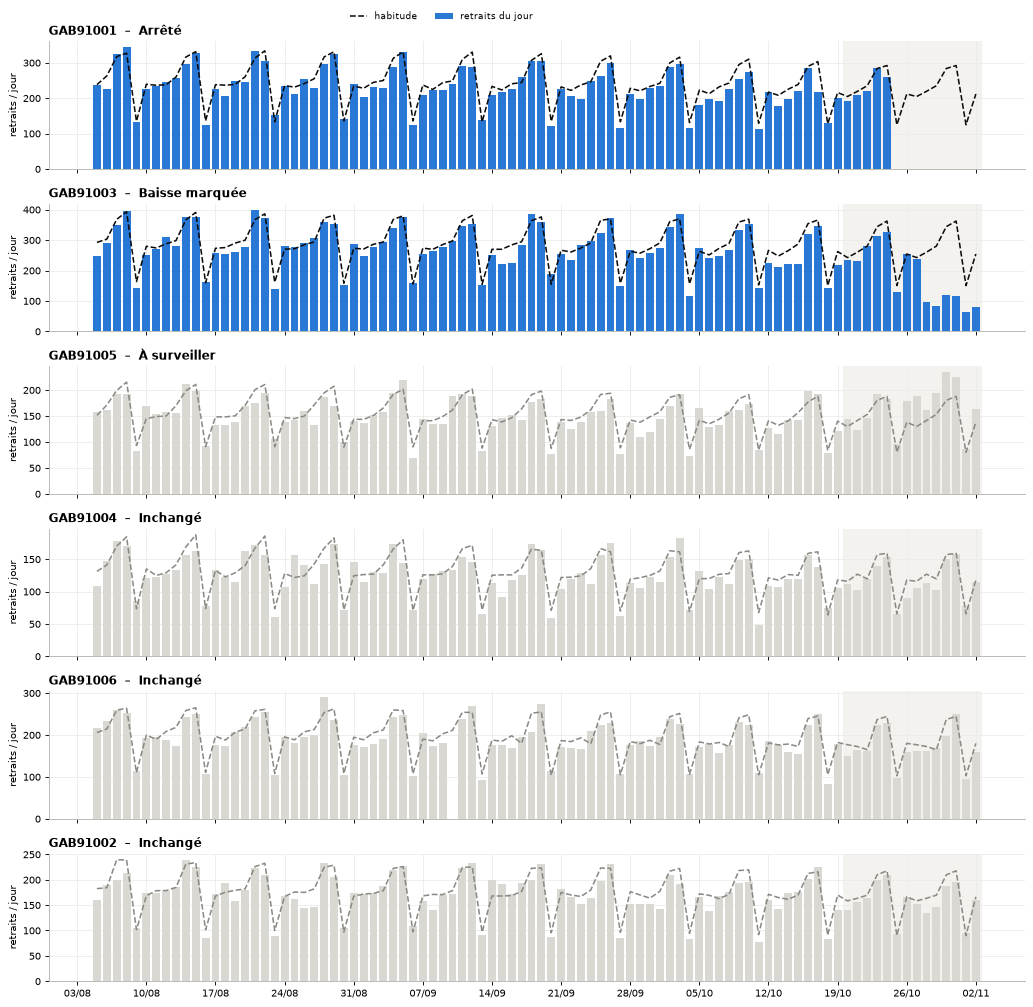

In [8]:
def tracer_derniers_jours(journees, tri, jours=90):
    """Un panneau par terminal : retraits du jour et habitude sur les 90 derniers jours, fenêtre récente en fond."""
    n = len(LISTE_TERMINAL)
    debut_recent = FIN_DONNEES - pd.Timedelta(days=JOURS_RECENTS - 1)
    statuts = tri.set_index("terminal")["statut"]
    fig, axes = plt.subplots(n, 1, figsize=(13, 2.1 * n), sharex=True)
    for ax, terminal in zip(np.atleast_1d(axes), tri["terminal"]):
        t = journees[journees["num_automate"] == terminal].set_index("date")["retraits"]
        habitude = sum(t.shift(7 * k) for k in range(1, 9)) / 8
        habitude[habitude.index >= debut_recent] = np.nan   # figée : habitude de la fenêtre = 8 semaines avant
        gel = t[(t.index >= debut_recent - pd.Timedelta(days=56)) & (t.index < debut_recent)]
        moyennes = gel.groupby(gel.index.dayofweek).mean()
        fenetre = t.index[t.index >= debut_recent]
        habitude.loc[fenetre] = moyennes.reindex(fenetre.dayofweek).values
        t, habitude = t[t.index > FIN_DONNEES - pd.Timedelta(days=jours)], habitude[habitude.index > FIN_DONNEES -
                                                                                    pd.Timedelta(days=jours)]
        ax.axvspan(debut_recent - pd.Timedelta(hours=12), FIN_DONNEES + pd.Timedelta(hours=12), color="#f3f2ef",
                   zorder=0)
        change = statuts[terminal] in ("Arrêté", "Baisse marquée", "Hausse marquée")
        ax.bar(t.index, t.values, width=0.8, color=BLEU if change else GRIS_CLAIR, linewidth=0, zorder=2,
               label="retraits du jour")
        ax.plot(habitude.index, habitude.values, color=ENCRE if change else GRIS, linewidth=1.4, linestyle="--",
                zorder=3, label="habitude")
        if DATE_MANIFESTATION:
            marquer_degradation(ax, pd.Timestamp(DATE_MANIFESTATION))
        ax.set_title("{}  –  {}".format(terminal, statuts[terminal]), loc="left")
        ax.set_ylim(bottom=0)
        ax.set_ylabel("retraits / jour")
    ax = np.atleast_1d(axes)[-1]
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    np.atleast_1d(axes)[0].legend(loc="upper left", ncol=2, frameon=False, fontsize=8, bbox_to_anchor=(0.3, 1.3))
    fig.tight_layout()
    plt.show()


afficher_titre("Les 90 derniers jours, terminal par terminal",
               "Fond gris : fenêtre examinée. Pointillés : habitude du terminal pour chaque jour. En bleu, les terminaux dont "
               "le comportement a changé ; en gris clair, les autres. Panneaux triés par statut.")
tracer_derniers_jours(journees, tri)

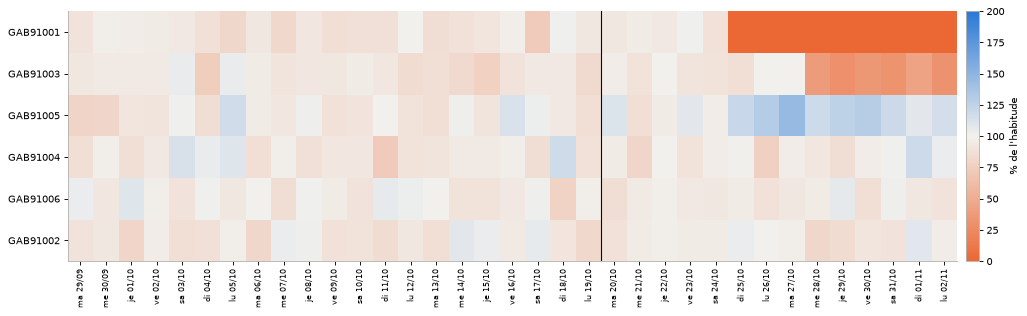

In [9]:
def tracer_calendrier_recent(journees, tri, jours=35):
    """terminal x derniers jours : retraits en % de l'habitude (mêmes jours de semaine des 8 semaines précédentes)."""
    debut = FIN_DONNEES - pd.Timedelta(days=jours - 1)
    lignes = {}
    for terminal in tri["terminal"]:
        t = journees[journees["num_automate"] == terminal].set_index("date")["retraits"]
        habitude = sum(t.shift(7 * k) for k in range(1, 9)) / 8
        lignes[terminal] = (100 * t / habitude.where(habitude > 0))[t.index >= debut]
    pivot = pd.DataFrame(lignes).T
    palette = LinearSegmentedColormap.from_list("ecart", [ORANGE, "#f2f1ee", BLEU])
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(pivot) + 1.3))
    image = ax.imshow(pivot.clip(0, 200).values, aspect="auto", cmap=palette, vmin=0, vmax=200,
                      interpolation="nearest")
    ax.set_yticks(range(len(pivot)))
    ax.set_yticklabels(pivot.index)
    ax.set_xticks(range(len(pivot.columns)))
    jours = ["lu", "ma", "me", "je", "ve", "sa", "di"]
    ax.set_xticklabels(["{} {}".format(jours[d.dayofweek], d.strftime("%d/%m")) for d in pivot.columns],
                       rotation=90, fontsize=7)
    ax.axvline(len(pivot.columns) - JOURS_RECENTS - 0.5, color=ENCRE, linewidth=1)
    ax.grid(False)
    barre = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
    barre.set_label("% de l'habitude")
    fig.tight_layout()
    plt.show()


afficher_titre("Les 5 dernières semaines jour par jour, en % de l'habitude",
               "Gris clair = journée normale (100 %), orange = sous l'habitude, orange vif = aucun retrait, bleu = "
               "au-dessus. Le trait noir sépare la fenêtre examinée (à droite). Un terminal touché apparaît comme une "
               "bande orange qui commence le même jour pour plusieurs terminaux ou juste après les manifestations.")
tracer_calendrier_recent(journees, tri)

## 5. Comportement normal des terminaux
Activité hebdomadaire sur toute la période, profil par jour de semaine et saisonnalité mensuelle : c'est la
référence à laquelle la période après dégradation est comparée.

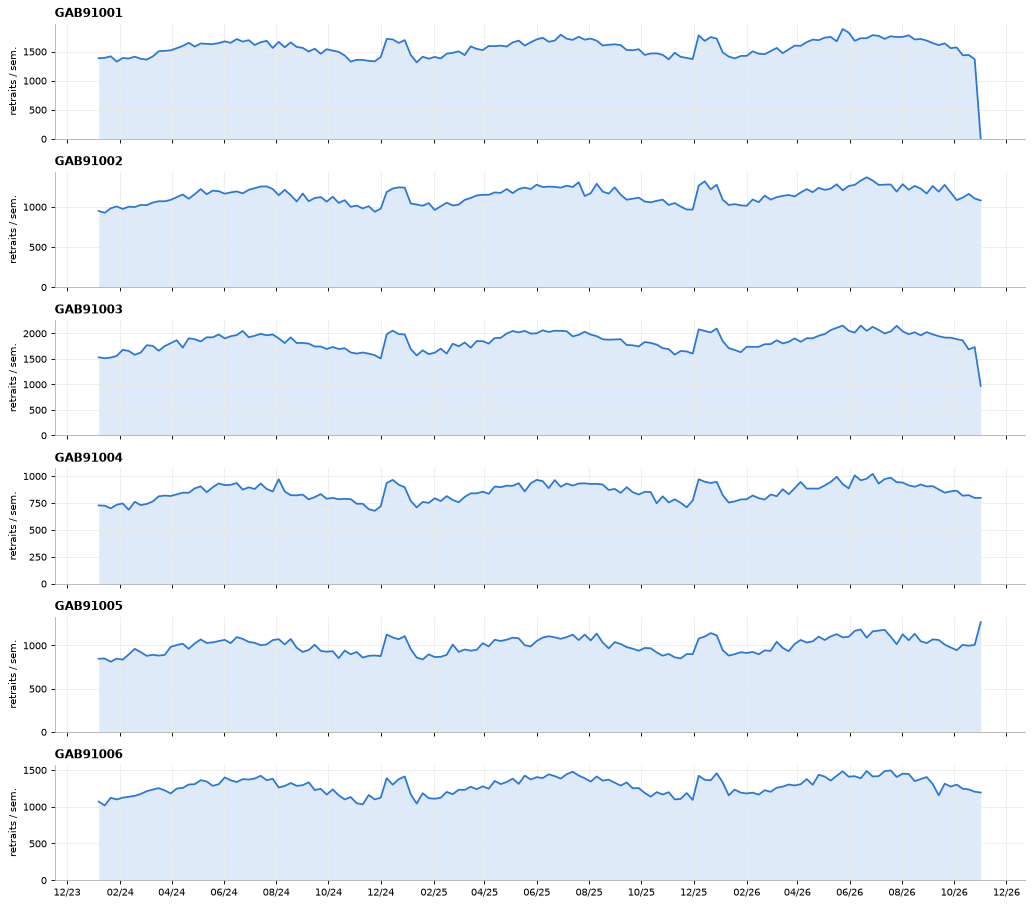

In [10]:
def tracer_historique(journees, dates):
    """Retraits par semaine sur toute la période, un panneau par terminal, même échelle de temps."""
    n = len(LISTE_TERMINAL)
    fig, axes = plt.subplots(n, 1, figsize=(13, 1.9 * n), sharex=True)
    for ax, terminal in zip(np.atleast_1d(axes), LISTE_TERMINAL):
        jours = journees[journees["num_automate"] == terminal].set_index("date")["retraits"].resample("W")
        semaine = jours.sum()[jours.count() == 7]          # semaines complètes seulement
        ax.fill_between(semaine.index, semaine.values, color=BLEU, alpha=0.15, linewidth=0)
        ax.plot(semaine.index, semaine.values, color=BLEU, linewidth=1.6)
        marquer_degradation(ax, dates.get(terminal), libelle=False)
        ax.set_title(terminal, loc="left")
        ax.set_ylabel("retraits / sem.")
        ax.set_ylim(bottom=0)
    np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
    fig.tight_layout()
    plt.show()


afficher_titre("Retraits par semaine depuis le début des données",
               "Chaque panneau a sa propre échelle verticale. Le trait noir marque la date de dégradation "
               "déclarée, ou à défaut la date des manifestations (si renseignées en section 1). Les creux de fin d'année ou d'été qui se répètent chaque "
               "année relèvent de la saisonnalité, pas d'un incident.")
tracer_historique(journees, {terminal: pd.Timestamp(DATES_DEGRADATION.get(terminal, DATE_MANIFESTATION))
                             for terminal in LISTE_TERMINAL if DATES_DEGRADATION.get(terminal, DATE_MANIFESTATION)})

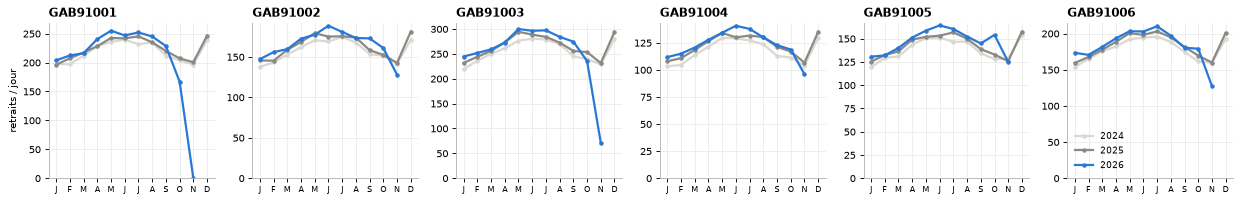

In [11]:
def profils_normaux(journees, fin_reference):
    """Moyenne des retraits par jour de semaine et par mois, avant la date de fin de référence de chaque terminal."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = journees[(journees["num_automate"] == terminal) & (journees["date"] < fin_reference.get(terminal, FIN_DONNEES))]
        semaine = t.groupby("jour_semaine")["retraits"].mean()
        lignes.append(pd.Series(semaine.values / semaine.mean() * 100, index=["lun", "mar", "mer", "jeu", "ven",
                                                                               "sam", "dim"][:len(semaine)],
                                name=terminal))
    return pd.DataFrame(lignes).round(0)


def tracer_saisonnalite(journees):
    """Retraits moyens par jour, mois par mois, une courbe par année (même terminal, même axe)."""
    n = len(LISTE_TERMINAL)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.6), sharey=False)
    teintes = {2024: GRIS_CLAIR, 2025: GRIS, 2026: BLEU}
    for ax, terminal in zip(np.atleast_1d(axes), LISTE_TERMINAL):
        t = journees[journees["num_automate"] == terminal]
        mensuel = t.groupby([t["date"].dt.year, t["date"].dt.month])["retraits"].mean().unstack(0)
        for annee in mensuel.columns:
            ax.plot(mensuel.index, mensuel[annee], color=teintes.get(annee, ORANGE), linewidth=2,
                    marker="o", markersize=3, label=str(annee))
        ax.set_title(terminal, loc="left")
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(list("JFMAMJJASOND"), fontsize=7)
        ax.set_ylim(bottom=0)
    np.atleast_1d(axes)[0].set_ylabel("retraits / jour")
    np.atleast_1d(axes)[-1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


afficher_titre("Saisonnalité : retraits moyens par jour, mois par mois",
               "Une courbe par année. Les années précédentes se superposent quand le comportement est stable ; "
               "l'écart de l'année en cours après la dégradation est l'impact recherché.")
tracer_saisonnalite(journees)

In [12]:
fin_ref_declaree = {terminal: pd.Timestamp(d) for terminal, d in DATES_DEGRADATION.items()}
afficher_tableau(profils_normaux(journees, fin_ref_declaree).reset_index().rename(columns={"index": "terminal"}),
                 "Profil par jour de semaine (indice 100 = moyenne du terminal)",
                 "Habitude de chaque terminal avant la dégradation : un indice de 130 le samedi signifie 30 % de "
                 "retraits de plus qu'un jour moyen.")

terminal,lun,mar,mer,jeu,ven,sam,dim
TERMINAL91001,97.0,91.0,97.0,102.0,126.0,132.0,55.0
TERMINAL91002,97.0,93.0,96.0,101.0,126.0,131.0,56.0
TERMINAL91003,97.0,91.0,96.0,102.0,126.0,132.0,55.0
TERMINAL91004,96.0,91.0,97.0,101.0,126.0,131.0,56.0
TERMINAL91005,96.0,92.0,95.0,102.0,126.0,133.0,56.0
TERMINAL91006,97.0,92.0,96.0,101.0,127.0,131.0,56.0


## 6. Date de rupture : déclarée et détectée
**Détection.** Pour chaque jour J, on compare les retraits des 7 jours J à J+6 à l'habitude : moyenne des
mêmes jours de semaine des 8 semaines précédant J. La rupture est le premier jour où ce rapport tombe sous
`SEUIL_RUPTURE` (50 %), puis on retient, dans cette semaine, le premier jour lui-même sous 50 % de son
habitude. Si `DATE_MANIFESTATION` est renseignée, la recherche se limite à 15 jours avant et
60 jours après ; sinon, elle porte sur les `JOURS_RECHERCHE` (60) derniers jours. En fin de données, la
semaine est raccourcie aux jours disponibles (3 au minimum).

**Date retenue** : la date déclarée si elle existe, sinon la date détectée, sinon la date des manifestations
(terminal sans rupture : on mesure alors l'absence d'impact à partir de cette date).

In [13]:
def rapport_habitude(serie):
    """Rapport : retraits des 7 jours J..J+6 / habitude (mêmes jours de semaine des 8 semaines avant J)."""
    # habitude du jour J+d = moyenne des jours J+d-7k (k = 1..8), tous antérieurs à J ; en fin de données,
    # seuls les jours disponibles comptent
    observes = [serie.shift(-d) for d in range(7)]
    habitudes = [(sum(serie.shift(7 * k - d) for k in range(1, 9)) / 8).where(observes[d].notna()) for d in range(7)]
    observe_7j = sum(o.fillna(0) for o in observes)
    habitude_7j = sum(h.fillna(0) for h in habitudes)
    disponibles = sum(o.notna().astype(int) for o in observes)
    return (observe_7j / habitude_7j.where(habitude_7j > 0)).where(disponibles >= 3)


def detecter_ruptures(journees, date_manif=None):
    """Date de rupture détectée par terminal (ou NaT), avec le rapport à l'habitude ce jour-là."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        serie = journees[journees["num_automate"] == terminal].set_index("date")["retraits"]
        rapport = rapport_habitude(serie)
        if date_manif:
            debut, fin = pd.Timestamp(date_manif) - pd.Timedelta(days=15), pd.Timestamp(date_manif) + pd.Timedelta(
                days=60)
        else:
            debut, fin = FIN_DONNEES - pd.Timedelta(days=JOURS_RECHERCHE - 1), FIN_DONNEES
        candidats = rapport[(rapport.index >= debut) & (rapport.index <= fin) & (rapport < SEUIL_RUPTURE)]
        date = candidats.index[0] if len(candidats) else pd.NaT
        if len(candidats):   # au jour près : premier jour de la semaine sous le seuil de sa propre habitude
            habitude_jour = sum(serie.shift(7 * k) for k in range(1, 9)) / 8
            semaine = serie[date:date + pd.Timedelta(days=6)]
            sous_seuil = semaine[semaine < SEUIL_RUPTURE * habitude_jour.reindex(semaine.index)]
            date = sous_seuil.index[0] if len(sous_seuil) else date
        lignes.append({"num_automate": terminal, "rupture_detectee": date,
                       "rapport_7j_pct": round(100 * candidats.iloc[0], 0) if len(candidats) else np.nan})
    return pd.DataFrame(lignes)


ruptures = detecter_ruptures(journees, DATE_MANIFESTATION)
ruptures["date_declaree"] = ruptures["num_automate"].map(lambda g: pd.Timestamp(DATES_DEGRADATION[g])
                                                         if g in DATES_DEGRADATION else pd.NaT)
secours = pd.Timestamp(DATE_MANIFESTATION) if DATE_MANIFESTATION else ruptures["rupture_detectee"].min()
ruptures["date_retenue"] = ruptures["date_declaree"].fillna(ruptures["rupture_detectee"]).fillna(secours)
ruptures["origine"] = np.where(ruptures["date_declaree"].notna(), "déclarée",
                               np.where(ruptures["rupture_detectee"].notna(), "détectée",
                                        "aucune rupture : date des manifestations"))
ruptures["ecart_jours"] = (ruptures["rupture_detectee"] - ruptures["date_declaree"]).dt.days
DATES = dict(zip(ruptures["num_automate"], ruptures["date_retenue"]))
affichage = ruptures.copy()
for c in ("rupture_detectee", "date_declaree", "date_retenue"):
    affichage[c] = affichage[c].dt.strftime("%d/%m/%Y").fillna("–")
afficher_tableau(affichage[["num_automate", "date_declaree", "rupture_detectee", "rapport_7j_pct", "ecart_jours",
                            "date_retenue", "origine"]],
                 "Date de rupture par terminal",
                 "rapport_7j_pct = activité des 7 jours suivant la rupture en % de l'habitude. Un écart de 0 à "
                 "quelques jours entre date déclarée et date détectée confirme que la baisse coïncide avec la "
                 "dégradation.")

num_automate,date_declaree,rupture_detectee,rapport_7j_pct,ecart_jours,date_retenue,origine
TERMINAL91001,–,25/10/2026,49.0,–,25/10/2026,détectée
TERMINAL91002,–,–,–,–,25/10/2026,aucune rupture : date des manifestations
TERMINAL91003,–,28/10/2026,43.0,–,28/10/2026,détectée
TERMINAL91004,–,–,–,–,25/10/2026,aucune rupture : date des manifestations
TERMINAL91005,–,–,–,–,25/10/2026,aucune rupture : date des manifestations
TERMINAL91006,–,–,–,–,25/10/2026,aucune rupture : date des manifestations


## 7. Activité attendue et activité observée
**Attendu (contrefactuel)** : habitude du terminal par jour de semaine sur la période de référence (6 mois avant la
date retenue, hors dernière semaine), multipliée par un indice de saisonnalité : rapport, l'année précédente,
entre l'activité autour du même jour (28 jours centrés) et l'activité moyenne sur la période de référence
décalée d'un an. Sans historique N-1, l'indice vaut 1.

In [14]:
def activite_attendue(journees, dates):
    """Ajoute à la table terminal x jour : retraits attendus, période (référence / avant / après) et rapport."""
    morceaux = []
    for terminal in LISTE_TERMINAL:
        t = journees[journees["num_automate"] == terminal].set_index("date").copy()
        date = dates[terminal]
        debut_ref = date - pd.Timedelta(days=JOURS_REFERENCE + JOURS_EXCLUS_AVANT)
        fin_ref = date - pd.Timedelta(days=JOURS_EXCLUS_AVANT)
        reference = t[(t.index >= debut_ref) & (t.index < fin_ref)]
        habitude = reference.groupby("jour_semaine")["retraits"].mean()
        lisse = t["retraits"].rolling(28, center=True, min_periods=14).mean()
        n_1 = lisse.shift(364)                                         # même jour de semaine, un an avant
        base_n_1 = t["retraits"].shift(364)[(t.index >= debut_ref) & (t.index < fin_ref)].mean()
        indice = (n_1 / base_n_1) if base_n_1 and base_n_1 > 0 else pd.Series(1.0, index=t.index)
        t["indice_saison"] = indice.fillna(1.0).clip(0.5, 2.0)
        t["attendu"] = t["jour_semaine"].map(habitude).values * t["indice_saison"]
        t["montant_attendu"] = t["attendu"] * reference["montant"].sum() / max(reference["retraits"].sum(), 1)
        t["periode"] = np.where(t.index >= date, "après",
                                np.where((t.index >= debut_ref) & (t.index < fin_ref), "référence", "avant"))
        t["jours_depuis"] = (t.index - date).days
        morceaux.append(t.reset_index())
    table = pd.concat(morceaux, ignore_index=True)
    table["attendu_7j"] = table.groupby("num_automate")["attendu"].transform(lambda s: s.rolling(7, 1).mean())
    table["observe_7j"] = table.groupby("num_automate")["retraits"].transform(lambda s: s.rolling(7, 1).mean())
    table["rapport_7j"] = table["observe_7j"] / table["attendu_7j"].where(table["attendu_7j"] > 0)
    return table


journees = activite_attendue(journees, DATES)
controle = journees[journees["periode"] == "référence"].groupby("num_automate").apply(
    lambda t: pd.Series({"retraits observés": t["retraits"].sum(), "retraits attendus": round(t["attendu"].sum()),
                         "écart %": round(100 * (t["retraits"].sum() / t["attendu"].sum() - 1), 1)})).reset_index()
afficher_tableau(controle, "Contrôle du contrefactuel sur la période de référence",
                 "Sur la période normale, observé et attendu doivent coïncider (écart proche de 0 %) : c'est la "
                 "preuve que l'attendu reproduit bien l'habitude du terminal.")

num_automate,retraits observés,retraits attendus,écart %
TERMINAL91001,44 057,44 040,0.0
TERMINAL91002,32 162,32 149,0.0
TERMINAL91003,52 099,52 047,0.1
TERMINAL91004,23 903,23 915,-0.0
TERMINAL91005,28 154,28 130,0.1
TERMINAL91006,35 899,35 940,-0.1


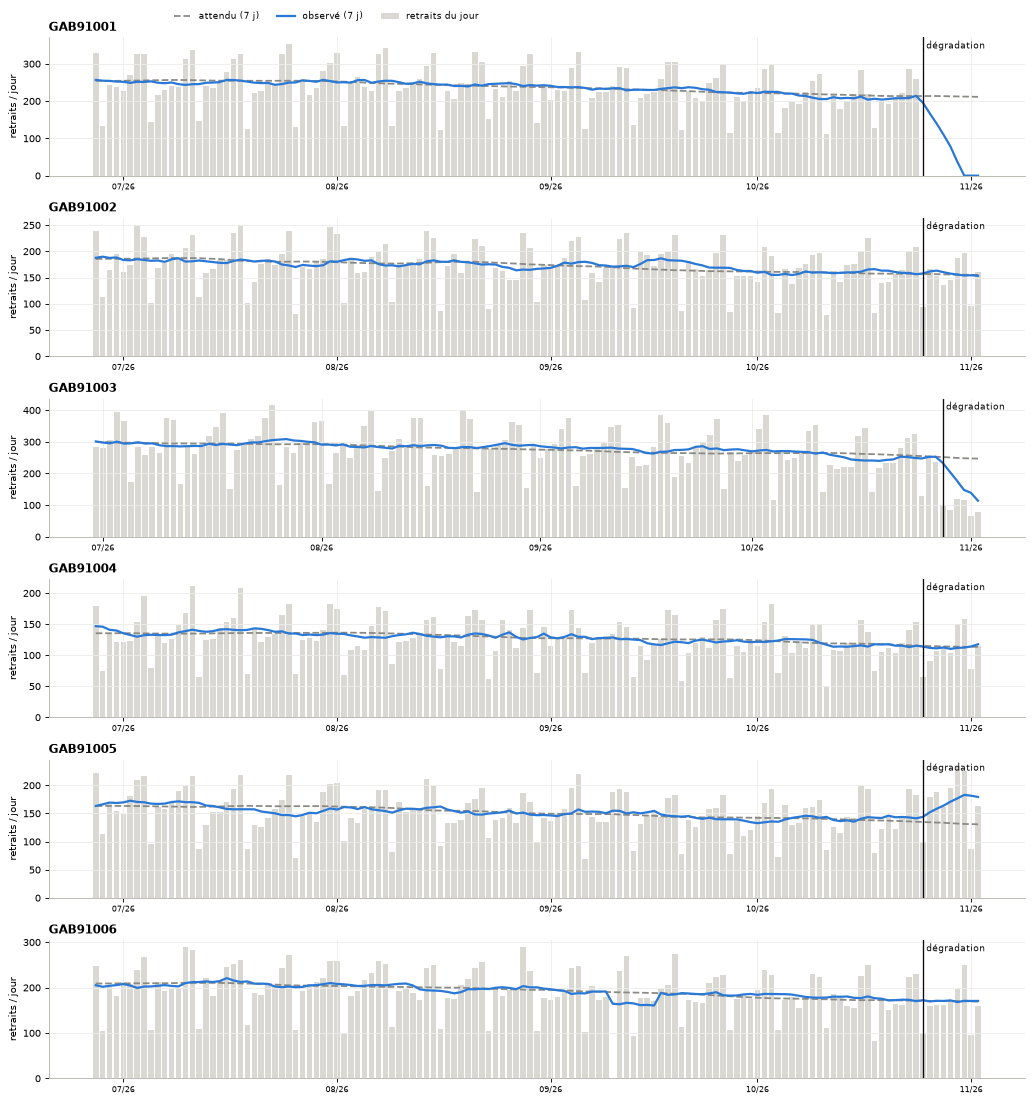

In [15]:
def tracer_observe_attendu(journees, jours_avant=120):
    """Un panneau par terminal : retraits du jour, moyenne 7 jours observée et attendue, autour de la dégradation."""
    n = len(LISTE_TERMINAL)
    fig, axes = plt.subplots(n, 1, figsize=(13, 2.3 * n))
    for ax, terminal in zip(np.atleast_1d(axes), LISTE_TERMINAL):
        t = journees[(journees["num_automate"] == terminal) & (journees["jours_depuis"] >= -jours_avant)]
        ax.bar(t["date"], t["retraits"], width=0.8, color=GRIS_CLAIR, linewidth=0, label="retraits du jour")
        ax.plot(t["date"], t["attendu_7j"], color=GRIS, linewidth=1.6, linestyle="--", label="attendu (7 j)")
        ax.plot(t["date"], t["observe_7j"], color=BLEU, linewidth=2, label="observé (7 j)")
        marquer_degradation(ax, DATES[terminal])
        ax.set_title(terminal, loc="left")
        ax.set_ylim(bottom=0)
        ax.set_ylabel("retraits / jour")
        axe_dates(ax)
    np.atleast_1d(axes)[0].legend(loc="upper left", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.12, 1.25))
    fig.tight_layout()
    plt.show()


afficher_titre("Observé et attendu autour de la dégradation",
               "Barres grises : retraits du jour. Pointillés : activité attendue sans incident (habitude + "
               "saisonnalité). Courbe bleue : activité observée. L'écart entre les deux après le trait noir est "
               "l'impact.")
tracer_observe_attendu(journees)

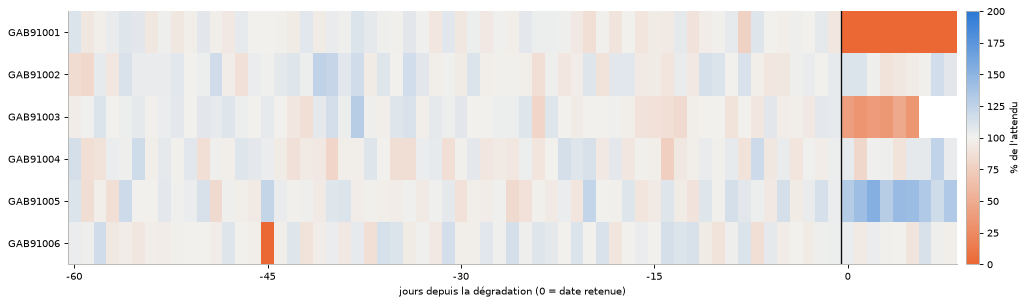

In [16]:
def tracer_carte_chaleur(journees, avant=60, apres=120):
    """terminal x jours depuis la dégradation : activité en % de l'attendu (orange = sous l'attendu)."""
    pivot = (journees[(journees["jours_depuis"] >= -avant) & (journees["jours_depuis"] <= apres)]
             .assign(pct=lambda t: 100 * t["retraits"] / t["attendu"].where(t["attendu"] > 0))
             .pivot_table(index="num_automate", columns="jours_depuis", values="pct"))
    palette = LinearSegmentedColormap.from_list("ecart", [ORANGE, "#f2f1ee", BLEU])
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(pivot) + 1.2))
    image = ax.imshow(pivot.clip(0, 200).values, aspect="auto", cmap=palette, vmin=0, vmax=200,
                      interpolation="nearest")
    ax.set_yticks(range(len(pivot)))
    ax.set_yticklabels(pivot.index)
    pas = list(range(0, pivot.shape[1], 15))
    ax.set_xticks(pas)
    ax.set_xticklabels([pivot.columns[i] for i in pas])
    ax.axvline(list(pivot.columns).index(0) - 0.5, color=ENCRE, linewidth=1.2)
    ax.set_xlabel("jours depuis la dégradation (0 = date retenue)")
    ax.grid(False)
    barre = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
    barre.set_label("% de l'attendu")
    fig.tight_layout()
    plt.show()


afficher_titre("Activité quotidienne en % de l'attendu, alignée sur la date de dégradation",
               "Chaque ligne est un terminal, chaque colonne un jour. Gris clair = activité normale (100 %), orange = "
               "activité sous l'attendu, orange vif = aucun retrait. Une bande orange continue après le trait = "
               "terminal hors service ; des rayures = fonctionnement intermittent.")
tracer_carte_chaleur(journees)

## 8. KPI avant / après / même période N-1
Période **avant** = période de référence ; période **après** = de la date retenue à la fin des données ;
**N-1** = mêmes dates que la période après, un an plus tôt (contrôle de la saisonnalité).

In [17]:
def kpi(t, jours_calendrier=None):
    """KPI d'une période (table terminal x jour d'un seul terminal)."""
    n = max(len(t), 1) if jours_calendrier is None else jours_calendrier
    retraits = t["retraits"].sum()
    return {"retraits / jour": retraits / n,
            "montant / jour (€)": t["montant"].sum() / n,
            "montant moyen (€)": t["montant"].sum() / retraits if retraits else np.nan,
            "jours sans retrait (%)": 100 * t["sans_retrait"].mean() if len(t) else np.nan,
            "heures actives / jour": t["heures_actives"].mean(),
            "retraits annulés (%)": 100 * t["retraits_annules"].sum() / max(retraits + t["retraits_annules"].sum(),
                                                                            1),
            "captures / 1000 opérations": 1000 * t["captures"].sum() / max(t["operations"].sum(), 1),
            "part de confrères (%)": 100 * t["retraits_confreres"].sum() / retraits if retraits else np.nan}


def tableau_kpi(journees):
    """Une ligne par terminal et par KPI : avant, après, N-1, variations."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = journees[journees["num_automate"] == terminal]
        apres = t[t["periode"] == "après"]
        n_1 = t[t["date"].isin(apres["date"] - pd.Timedelta(days=364))]
        k_avant, k_apres, k_n1 = kpi(t[t["periode"] == "référence"]), kpi(apres), kpi(n_1) if len(n_1) else {}
        for nom in k_avant:
            avant, ap, n1 = k_avant[nom], k_apres[nom], k_n1.get(nom, np.nan)
            variation = lambda a, b: 100 * (a / b - 1) if b and not pd.isna(b) and not pd.isna(a) else np.nan
            lignes.append({"terminal": terminal, "KPI": nom, "avant": avant, "après": ap, "N-1 même période": n1,
                           "après vs avant": variation(ap, avant), "après vs N-1": variation(ap, n1)})
    return pd.DataFrame(lignes)


kpis = tableau_kpi(journees)
for terminal in LISTE_TERMINAL:
    afficher_tableau(kpis[kpis["terminal"] == terminal].drop(columns="terminal"),
                     "KPI {} (dégradation retenue le {})".format(terminal, DATES[terminal].strftime("%d/%m/%Y")),
                     colonnes_variation=("après vs avant", "après vs N-1"))

KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,242.1,0.0,188.2,-100 %,-100 %
montant / jour (€),19 769,0.0,15 680,-100 %,-100 %
montant moyen (€),81.7,–,83.3,–,–
jours sans retrait (%),0.0,100.0,0.0,–,–
heures actives / jour,21.3,0.0,21.0,-100 %,-100 %
retraits annulés (%),1.0,0.0,1.0,-100 %,-100 %
captures / 1000 opérations,6.3,0.0,5.8,-100 %,-100 %
part de confrères (%),38.3,–,37.7,–,–


KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,176.7,148.1,143.1,-16 %,+3 %
montant / jour (€),14 408,12 306,11 596,-15 %,+6 %
montant moyen (€),81.5,83.1,81.0,+2 %,+3 %
jours sans retrait (%),0.0,0.0,0.0,–,–
heures actives / jour,20.6,20.8,20.1,+1 %,+3 %
retraits annulés (%),1.0,1.2,0.8,+18 %,+54 %
captures / 1000 opérations,6.5,5.9,6.9,-10 %,-14 %
part de confrères (%),38.4,37.8,37.7,-2 %,+0 %


KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,286.3,93.3,238.0,-67 %,-61 %
montant / jour (€),23 336,4 230,19 460,-82 %,-78 %
montant moyen (€),81.5,45.3,81.8,-44 %,-45 %
jours sans retrait (%),0.0,0.0,0.0,–,–
heures actives / jour,21.6,19.2,20.8,-11 %,-8 %
retraits annulés (%),1.0,7.0,0.6,+622 %,+1152 %
captures / 1000 opérations,6.0,29.0,6.9,+388 %,+320 %
part de confrères (%),38.0,42.1,38.2,+11 %,+10 %


KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,131.3,108.7,103.8,-17 %,+5 %
montant / jour (€),10 693,8 838,8 666,-17 %,+2 %
montant moyen (€),81.4,81.3,83.5,-0 %,-3 %
jours sans retrait (%),0.0,0.0,0.0,–,–
heures actives / jour,20.0,18.6,19.1,-7 %,-3 %
retraits annulés (%),1.1,1.7,1.1,+51 %,+61 %
captures / 1000 opérations,5.7,5.0,2.1,-13 %,+137 %
part de confrères (%),37.8,40.8,37.3,+8 %,+9 %


KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,154.7,170.1,121.1,+10 %,+40 %
montant / jour (€),12 631,13 470,9 404,+7 %,+43 %
montant moyen (€),81.7,79.2,77.7,-3 %,+2 %
jours sans retrait (%),0.0,0.0,0.0,–,–
heures actives / jour,20.3,21.0,19.2,+4 %,+9 %
retraits annulés (%),1.0,0.9,1.3,-13 %,-29 %
captures / 1000 opérations,5.7,3.9,7.2,-32 %,-46 %
part de confrères (%),37.9,37.4,36.9,-1 %,+1 %


KPI,avant,après,N-1 même période,après vs avant,après vs N-1
retraits / jour,197.2,161.2,158.9,-18 %,+1 %
montant / jour (€),16 090,12 918,13 122,-20 %,-2 %
montant moyen (€),81.6,80.1,82.6,-2 %,-3 %
jours sans retrait (%),0.5,0.0,0.0,-100 %,–
heures actives / jour,20.8,20.8,20.7,-0 %,+1 %
retraits annulés (%),1.1,0.8,0.9,-24 %,-9 %
captures / 1000 opérations,5.9,4.8,4.8,-20 %,-1 %
part de confrères (%),38.2,39.0,39.7,+2 %,-2 %


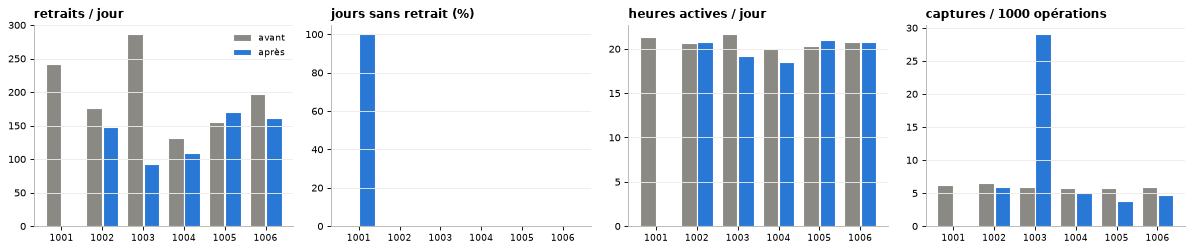

In [18]:
def tracer_kpi_principaux(kpis):
    """Avant / après pour les 4 KPI principaux, un panneau par KPI, une paire de barres par terminal."""
    noms = ["retraits / jour", "jours sans retrait (%)", "heures actives / jour", "captures / 1000 opérations"]
    fig, axes = plt.subplots(1, len(noms), figsize=(15, 3.2))
    x = np.arange(len(LISTE_TERMINAL))
    for ax, nom in zip(axes, noms):
        t = kpis[kpis["KPI"] == nom].set_index("terminal").reindex(LISTE_TERMINAL)
        ax.bar(x - 0.2, t["avant"], width=0.38, color=GRIS, label="avant", edgecolor="white", linewidth=1)
        ax.bar(x + 0.2, t["après"], width=0.38, color=BLEU, label="après", edgecolor="white", linewidth=1)
        ax.set_title(nom, loc="left")
        ax.set_xticks(x)
        ax.set_xticklabels([g[-4:] for g in LISTE_TERMINAL], fontsize=8)
        ax.xaxis.grid(False)
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


afficher_titre("Avant / après : les 4 KPI principaux",
               "Gris = période de référence, bleu = depuis la dégradation. terminal repérés par les 4 derniers caractères.")
tracer_kpi_principaux(kpis)

## 9. Changement de comportement dans la journée et dans les opérations
Un terminal peut rester ouvert mais fonctionner différemment : plages horaires réduites, une cassette vide (une
coupure disparaît), plus de captures ou d'annulations (lecteur ou distributeur endommagé).

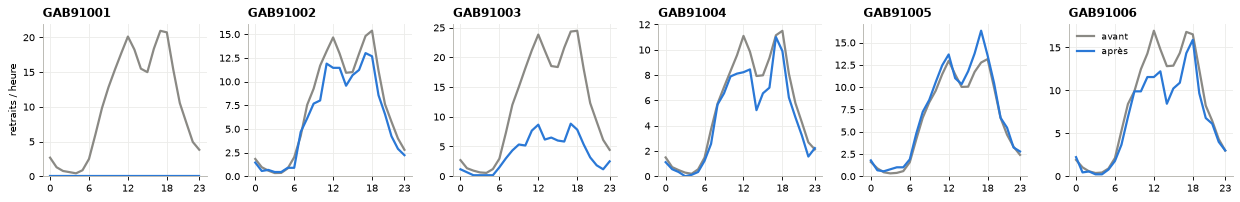

In [19]:
def tracer_profils_horaires(heure_brut, journees):
    """Retraits moyens par heure, avant et après, un panneau par terminal."""
    periodes = journees[["num_automate", "date", "periode"]]
    t = heure_brut.merge(periodes, on=["num_automate", "date"])
    n_jours = periodes.groupby(["num_automate", "periode"]).size()
    n = len(LISTE_TERMINAL)
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.6), sharey=False)
    for ax, terminal in zip(np.atleast_1d(axes), LISTE_TERMINAL):
        for periode, couleur in (("référence", GRIS), ("après", BLEU)):
            s = t[(t["num_automate"] == terminal) & (t["periode"] == periode)].groupby("heure")["retraits"].sum()
            jours = n_jours.get((terminal, periode), 0)
            if jours:
                s = (s / jours).reindex(range(24), fill_value=0)
                ax.plot(s.index, s.values, color=couleur, linewidth=2,
                        label="avant" if periode == "référence" else "après")
        ax.set_title(terminal, loc="left")
        ax.set_xticks([0, 6, 12, 18, 23])
        ax.set_ylim(bottom=0)
    np.atleast_1d(axes)[0].set_ylabel("retraits / heure")
    np.atleast_1d(axes)[-1].legend(frameon=False, fontsize=8)
    fig.tight_layout()
    plt.show()


afficher_titre("Profil horaire avant / après",
               "Retraits moyens par heure. Une courbe « après » plate = terminal arrêté ; une courbe abaissée de la "
               "même forme = baisse de fréquentation ; une forme différente = plages horaires modifiées.")
tracer_profils_horaires(heure_brut, journees)

In [20]:
def tableau_coupures(coupures, dates):
    """Part des billets délivrés par valeur de coupure, avant et après (en %)."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = coupures[coupures["num_automate"] == terminal]
        date = dates[terminal]
        for periode, masque in (("avant", (t["mois"] < date.replace(day=1)) &
                                 (t["mois"] >= date - pd.Timedelta(days=JOURS_REFERENCE))),
                                ("après", t["mois"] > date)):
            s = t[masque].groupby("coupure")["billets"].sum()
            if s.sum():
                ligne = {"terminal": terminal, "période": periode}
                ligne.update({"{:.0f} €".format(k): round(100 * v / s.sum(), 1) for k, v in s.items()})
                lignes.append(ligne)
    return pd.DataFrame(lignes).fillna(0)


afficher_tableau(tableau_coupures(coupures, DATES), "Billets délivrés par coupure (% des billets)",
                 "Une coupure qui passe à 0 % après la dégradation = cassette vide ou hors service : le terminal "
                 "fonctionne en mode dégradé (montants limités).")

terminal,période,20 €,50 €
TERMINAL91001,avant,75.0,25.0
TERMINAL91002,avant,75.1,24.9
TERMINAL91002,après,72.2,27.8
TERMINAL91003,avant,75.0,25.0
TERMINAL91003,après,100.0,0.0
TERMINAL91004,avant,75.7,24.3
TERMINAL91004,après,75.1,24.9
TERMINAL91005,avant,74.7,25.3
TERMINAL91005,après,75.0,25.0
TERMINAL91006,avant,74.5,25.5


In [21]:
def tableau_motifs(motifs, dates):
    """Captures par motif, par mois en moyenne, avant et après."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = motifs[motifs["num_automate"] == terminal]
        date = dates[terminal]
        avant = t[(t["mois"] < date.replace(day=1)) & (t["mois"] >= date - pd.Timedelta(days=JOURS_REFERENCE))]
        apres = t[t["mois"] > date]
        n_avant, n_apres = max(avant["mois"].nunique(), 1), max(apres["mois"].nunique(), 1)
        for motif in sorted(set(t["motif_capture"])):
            lignes.append({"terminal": terminal, "motif": motif or "(vide)",
                           "captures / mois avant": avant[avant["motif_capture"] == motif]["captures"].sum() / n_avant,
                           "captures / mois après": apres[apres["motif_capture"] == motif]["captures"].sum() / n_apres})
    table = pd.DataFrame(lignes)
    if len(table):
        table["variation"] = 100 * (table["captures / mois après"] / table["captures / mois avant"].where(
            table["captures / mois avant"] > 0) - 1)
    return table


afficher_tableau(tableau_motifs(motifs, DATES), "Captures de carte par motif, avant / après",
                 "Une hausse des « incidents lecture » ou « oubli de carte » après la dégradation signale un "
                 "lecteur de carte endommagé.", colonnes_variation=("variation",))

terminal,motif,captures / mois avant,captures / mois après,variation
TERMINAL91001,INCIDENT LECTURE CARTE,17.2,0.0,-100 %
TERMINAL91001,NOMBRE ESSAIS CODE CONFIDENTIEL DEPASSE,14.2,0.0,-100 %
TERMINAL91001,OUBLI DE CARTE,16.2,0.0,-100 %
TERMINAL91002,INCIDENT LECTURE CARTE,13.2,0.0,-100 %
TERMINAL91002,NOMBRE ESSAIS CODE CONFIDENTIEL DEPASSE,14.8,0.0,-100 %
TERMINAL91002,OUBLI DE CARTE,9.0,0.0,-100 %
TERMINAL91003,INCIDENT LECTURE CARTE,20.4,2.0,-90 %
TERMINAL91003,NOMBRE ESSAIS CODE CONFIDENTIEL DEPASSE,16.8,1.0,-94 %
TERMINAL91003,OUBLI DE CARTE,19.0,1.0,-95 %
TERMINAL91004,INCIDENT LECTURE CARTE,8.0,0.0,-100 %


## 10. Preuve statistique, durée d'indisponibilité et manque à gagner
**Test de Mann-Whitney** : l'activité quotidienne rapportée à l'attendu (donc corrigée du jour de semaine et
de la saison) est-elle significativement plus basse après la dégradation que pendant la période de référence ? (test sur les rangs, sans hypothèse de loi normale ; p < 0,01 = baisse
significative). **Retraits non servis** = retraits attendus moins retraits observés, cumulés depuis la dégradation ;
**montant non distribué** = même calcul sur les montants (attendu = retraits attendus x montant moyen habituel).

In [22]:
def mann_whitney(avant, apres):
    """Test unilatéral (après < avant) par approximation normale ; renvoie (statistique z, p-valeur)."""
    avant, apres = np.asarray(avant, float), np.asarray(apres, float)
    avant, apres = avant[~np.isnan(avant)], apres[~np.isnan(apres)]
    if len(avant) < 5 or len(apres) < 5:
        return np.nan, np.nan
    rangs = pd.Series(np.concatenate([avant, apres])).rank().values
    n1, n2 = len(avant), len(apres)
    u = rangs[n1:].sum() - n2 * (n2 + 1) / 2
    ecart = math.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
    z = (u - n1 * n2 / 2) / ecart
    return z, 0.5 * math.erfc(-z / math.sqrt(2))


def date_reprise(t):
    """Premier jour après la dégradation où l'activité 7 jours atteint SEUIL_REPRISE de l'attendu, en
    restant au-dessus du seuil de rupture ensuite pendant 14 jours."""
    apres = t[t["periode"] == "après"].reset_index(drop=True)
    for i in range(len(apres)):
        fenetre = apres["rapport_7j"].iloc[i:i + 14]
        if apres["rapport_7j"].iloc[i] >= SEUIL_REPRISE and len(fenetre) == 14 and (fenetre >= SEUIL_RUPTURE).all():
            return apres["date"].iloc[i] - pd.Timedelta(days=6)   # début de la semaine qui atteint le seuil
    return pd.NaT


def diagnostic(journees, ruptures):
    """Statut, durée d'indisponibilité, retraits non servis et preuve statistique par terminal."""
    lignes = []
    for terminal in LISTE_TERMINAL:
        t = journees[journees["num_automate"] == terminal]
        ref, apres = t[t["periode"] == "référence"], t[t["periode"] == "après"]
        recent = apres.tail(28)
        rapport_apres = apres["retraits"].sum() / max(apres["attendu"].sum(), 1e-9)
        rapport_recent = recent["retraits"].sum() / max(recent["attendu"].sum(), 1e-9)
        a_rupture = not pd.isna(ruptures.set_index("num_automate").loc[terminal, "rupture_detectee"])
        reprise = date_reprise(t) if a_rupture else pd.NaT
        part_zero = apres["sans_retrait"].mean()
        if rapport_recent < SEUIL_HORS_SERVICE:
            statut = "Hors service"
        elif not a_rupture and rapport_apres >= 1.2:
            statut = "Hausse d'activité (report probable)"
        elif not a_rupture and rapport_apres >= SEUIL_REPRISE:
            statut = "Pas d'impact visible"
        elif not pd.isna(reprise) and rapport_recent >= SEUIL_REPRISE:
            statut = "Remis en service"
        elif part_zero >= 0.3:
            statut = "Fonctionnement intermittent"
        else:
            statut = "Activité réduite"
        indisponible = apres["retraits"] < SEUIL_HORS_SERVICE * apres["attendu"]
        manque = max(apres["attendu"].sum() - apres["retraits"].sum(), 0)
        manque_montant = max(apres["montant_attendu"].sum() - apres["montant"].sum(), 0)
        z, p = mann_whitney(ref["retraits"] / ref["attendu"].where(ref["attendu"] > 0),
                            apres["retraits"] / apres["attendu"].where(apres["attendu"] > 0))
        derniere = t.loc[t["retraits"] > 0, "date"].max()
        lignes.append({
            "terminal": terminal, "statut": statut, "date retenue": DATES[terminal].strftime("%d/%m/%Y"),
            "date de reprise": reprise.strftime("%d/%m/%Y") if not pd.isna(reprise) else "–",
            "jours d'indisponibilité": int(indisponible.sum()),
            "dernier retrait": derniere.strftime("%d/%m/%Y") if not pd.isna(derniere) else "–",
            "activité depuis (% attendu)": round(100 * rapport_apres, 0),
            "activité 28 derniers jours (%)": round(100 * rapport_recent, 0),
            "retraits non servis": int(round(manque)),
            "montant non distribué (€)": int(round(manque_montant)),
            "baisse significative": "oui (p < 0,001)" if p < 0.001 else ("oui (p = {:.3f})".format(p) if p < 0.01
                                                                          else "non (p = {:.2f})".format(p))})
    return pd.DataFrame(lignes)


synthese = diagnostic(journees, ruptures)
afficher_tableau(synthese, "Diagnostic par terminal",
                 "Jours d'indisponibilité : jours depuis la dégradation avec moins de 10 % de l'activité attendue. "
                 "Baisse significative : test de Mann-Whitney, p-valeur inférieure à 0,01. Retraits non servis et "
                 "montant non distribué : attendu moins observé, cumulés depuis la dégradation (estimation).")

terminal,statut,date retenue,date de reprise,jours d'indisponibilité,dernier retrait,activité depuis (% attendu),activité 28 derniers jours (%),retraits non servis,montant non distribué (€),baisse significative
TERMINAL91001,Hors service,25/10/2026,–,9,24/10/2026,0.0,0.0,1 800,146 977,"oui (p < 0,001)"
TERMINAL91002,Pas d'impact visible,25/10/2026,–,0,02/11/2026,101.0,101.0,0,0,non (p = 0.77)
TERMINAL91003,Activité réduite,28/10/2026,–,0,02/11/2026,37.0,37.0,942,97 072,"oui (p < 0,001)"
TERMINAL91004,Pas d'impact visible,25/10/2026,–,0,02/11/2026,101.0,101.0,0,0,non (p = 0.81)
TERMINAL91005,Hausse d'activité (report probable),25/10/2026,–,0,02/11/2026,137.0,137.0,0,0,non (p = 1.00)
TERMINAL91006,Pas d'impact visible,25/10/2026,–,0,02/11/2026,100.0,100.0,0,1 667,non (p = 0.54)


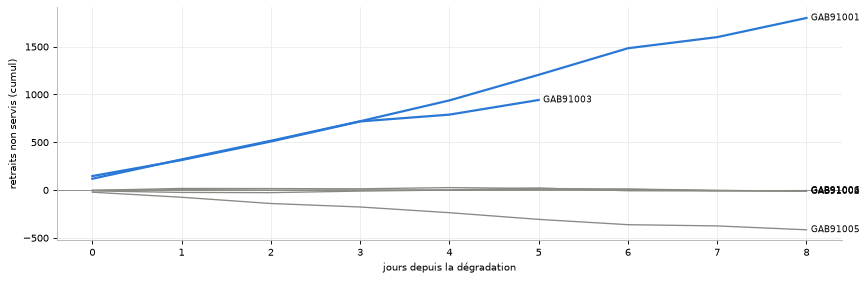

In [23]:
def tracer_manque(synthese, journees):
    """Retraits non servis cumulés depuis la dégradation, une courbe par terminal (même axe : jours depuis)."""
    fig, ax = plt.subplots(figsize=(11, 3.6))
    for terminal in synthese.sort_values("retraits non servis", ascending=False)["terminal"]:
        t = journees[(journees["num_automate"] == terminal) & (journees["periode"] == "après")]
        cumul = (t["attendu"] - t["retraits"]).cumsum()
        impact = synthese.set_index("terminal").loc[terminal, "statut"] not in ("Pas d'impact visible",
                                                                     "Hausse d'activité (report probable)")
        ax.plot(t["jours_depuis"], cumul, color=BLEU if impact else GRIS, linewidth=2 if impact else 1.2)
        ax.annotate(terminal, (t["jours_depuis"].iloc[-1], cumul.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    fontsize=8, va="center", color=ENCRE)
    ax.set_xlabel("jours depuis la dégradation")
    ax.set_ylabel("retraits non servis (cumul)")
    ax.axhline(0, color=GRIS, linewidth=0.8)
    fig.tight_layout()
    plt.show()


afficher_titre("Retraits non servis cumulés depuis la dégradation",
               "Une courbe qui monte en ligne droite = terminal totalement arrêté ; une courbe qui se stabilise = terminal "
               "remis en service ; une courbe qui descend sous 0 = activité au-dessus de l'attendu. En gris : terminal "
               "sans impact (ou en hausse).")
tracer_manque(synthese, journees)

## 11. Synthèse
Chiffres clés de l'ensemble des terminaux et une phrase par terminal, reprenables telles quelles dans une présentation.

In [24]:
def phrase(ligne):
    """Phrase de synthèse d'un terminal."""
    debut = "{} ({}) : ".format(ligne["terminal"], fiche.set_index("num_automate").loc[ligne["terminal"], "ville"] or "")
    if ligne["statut"] == "Hors service":
        texte = "hors service depuis le {} (dernier retrait le {}), {} jours d'indisponibilité".format(
            ligne["date retenue"], ligne["dernier retrait"], ligne["jours d'indisponibilité"])
    elif ligne["statut"] == "Remis en service":
        texte = "arrêté le {}, remis en service le {} après {} jours d'indisponibilité".format(
            ligne["date retenue"], ligne["date de reprise"], ligne["jours d'indisponibilité"])
    elif ligne["statut"] == "Fonctionnement intermittent":
        texte = "fonctionnement intermittent depuis le {} ({} jours d'indisponibilité), activité à {:.0f} % de " \
                "l'attendu".format(ligne["date retenue"], ligne["jours d'indisponibilité"],
                                   ligne["activité depuis (% attendu)"])
    elif ligne["statut"] == "Activité réduite":
        texte = "activité réduite à {:.0f} % de l'attendu depuis le {}".format(ligne["activité depuis (% attendu)"],
                                                                               ligne["date retenue"])
    elif ligne["statut"].startswith("Hausse"):
        return debut + "activité en hausse, à {:.0f} % de l'attendu depuis le {} : report probable des clients " \
                       "des terminaux touchés.".format(ligne["activité depuis (% attendu)"], ligne["date retenue"])
    else:
        return debut + "pas d'impact visible : activité à {:.0f} % de l'attendu.".format(
            ligne["activité depuis (% attendu)"])
    return debut + texte + " ; {} retraits non servis, environ {} € non distribués.".format(
        formater(ligne["retraits non servis"]), formater(ligne["montant non distribué (€)"]))


impactes = synthese[~synthese["statut"].isin(["Pas d'impact visible", "Hausse d'activité (report probable)"])]
afficher_chiffres({"terminal impactés": "{} / {}".format(len(impactes), len(synthese)),
                   "terminal hors service à ce jour": int((synthese["statut"] == "Hors service").sum()),
                   "jours d'indisponibilité cumulés": int(synthese["jours d'indisponibilité"].sum()),
                   "retraits non servis": int(impactes["retraits non servis"].sum()),
                   "montant non distribué (€)": int(impactes["montant non distribué (€)"].sum())},
                  "Impact des manifestations")
display(HTML(CSS + "<ul class='note' style='font-size:13px'>{}</ul>".format(
    "".join("<li>{}</li>".format(phrase(l)) for _, l in synthese.iterrows()))))

In [25]:
if DATASET_SORTIE_SYNTHESE:
    import dataiku
    dataiku.Dataset(DATASET_SORTIE_SYNTHESE).write_with_schema(synthese)
    print("Synthèse écrite dans", DATASET_SORTIE_SYNTHESE)